In [1]:
!pip install yfinance statsmodels -q


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [5]:
import sys
print(sys.executable)

/Library/Developer/CommandLineTools/usr/bin/python3


In [6]:
import sys
!{sys.executable} -m pip install numpy pandas yfinance matplotlib statsmodels scipy scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple
     |████████████████████████████████| 5.3 MB 435 kB/s eta 0:00:01
     |████████████████████████████████| 10.8 MB 327 kB/s eta 0:00:01
     |████████████████████████████████| 149 kB 318 kB/s eta 0:00:01
     |████████████████████████████████| 7.8 MB 108 kB/s eta 0:00:01
     |████████████████████████████████| 10.0 MB 196 kB/s eta 0:00:01
     |████████████████████████████████| 30.3 MB 248 kB/s eta 0:00:01    |███████▎                        | 6.9 MB 173 kB/s eta 0:02:15
     |████████████████████████████████| 11.1 MB 177 kB/s eta 0:00:01
     |████████████████████████████████| 347 kB 228 kB/s eta 0:00:01
     |████████████████████████████████| 506 kB 231 kB/s eta 0:00:01
     |████████████████████████████████| 173 kB 137 kB/s eta 0:00:01
     |████████████████████████████████| 427 kB 458 kB/s eta 0:00:01
     |████████████████████████████████| 194

In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.tsa.stattools import coint, adfuller

print("Everything works!")

/Users/xts/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Matplotlib is building the font cache; this may take a moment.


Everything works!


In [8]:
tickers = [
    "AAPL", "MSFT", "GOOGL", "META", "AMZN",
    "JPM", "BAC", "GS", "MS", "WFC",
    "KO", "PEP", "WMT", "COST", "MCD",
    "XOM", "CVX",
    "V", "MA",
    "HD", "LOW",
    "CAT", "DE",
    "UPS", "FDX"
]

prices = yf.download(
    tickers,
    start="2016-01-01",
    end="2025-12-31",
    auto_adjust=True,
    progress=False
)["Close"]

print(prices.shape)
prices.head()

(2513, 25)


Ticker,AAPL,AMZN,BAC,CAT,COST,CVX,DE,FDX,GOOGL,GS,...,MCD,META,MS,MSFT,PEP,UPS,V,WFC,WMT,XOM
Date,,,,,,,,,,,,,,,,,,,,,
2016-01-04,23.688673,31.849501,12.988195,52.891811,133.654022,56.349926,63.908756,97.845947,37.614075,142.279938,...,90.398720,101.250259,23.331135,47.680958,70.908020,62.805614,70.156303,39.249702,16.966854,49.002319
2016-01-05,23.095043,31.689501,12.988195,52.339485,133.980789,56.831932,64.278374,98.678192,37.717587,139.830185,...,91.644211,101.755409,23.182899,47.898487,71.396217,63.428127,70.684547,39.234890,17.369909,49.419838
2016-01-06,22.643087,31.632500,12.711516,51.514877,132.740982,54.586788,63.555973,96.031319,37.608631,136.416550,...,91.029160,101.993134,22.604816,47.028389,71.417732,62.527466,69.757797,38.485641,17.543833,49.008644
2016-01-07,21.687449,30.396999,12.253013,49.741196,129.699905,52.652447,62.993137,91.815399,36.700764,132.223801,...,88.922562,96.991035,21.478281,45.392635,70.046539,61.322231,68.386177,37.387753,17.952408,48.224213
2016-01-08,21.802128,30.352501,12.015860,49.235527,127.429665,52.087994,61.959919,91.897285,36.201031,131.677643,...,88.784164,96.406639,21.033600,45.531845,69.788086,60.520939,67.542809,36.764614,17.541067,47.249973


In [9]:
# Check missing values
print("Missing values before cleaning:")
print(prices.isnull().sum().sort_values(ascending=False).head())

# Forward fill missing prices, then remove any remaining missing rows
prices = prices.ffill().dropna()

print("\nData shape after cleaning:")
print(prices.shape)

print("\nTotal missing values:")
print(prices.isnull().sum().sum())

Missing values before cleaning:
Ticker
AAPL    0
LOW     0
WMT     0
WFC     0
V       0
dtype: int64

Data shape after cleaning:
(2513, 25)

Total missing values:
0


In [10]:
# Split data into in-sample (training) and out-of-sample (testing)

train = prices.loc[:"2022-12-31"]
test = prices.loc["2023-01-01":]

print("Training period:")
print(train.index.min(), "to", train.index.max())
print("Shape:", train.shape)

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())
print("Shape:", test.shape)

Training period:
2016-01-04 00:00:00 to 2022-12-30 00:00:00
Shape: (1762, 25)

Testing period:
2023-01-03 00:00:00 to 2025-12-30 00:00:00
Shape: (751, 25)


In [11]:
from itertools import combinations
from statsmodels.tsa.stattools import coint

results = []

for stock1, stock2 in combinations(train.columns, 2):
    
    series1 = np.log(train[stock1])
    series2 = np.log(train[stock2])
    
    score, pvalue, _ = coint(series1, series2)
    
    results.append({
        "Stock 1": stock1,
        "Stock 2": stock2,
        "p-value": pvalue
    })

# Convert results into DataFrame
cointegration_results = pd.DataFrame(results)

# Sort from strongest to weakest evidence of cointegration
cointegration_results = cointegration_results.sort_values("p-value")

# Show top 10 pairs
cointegration_results.head(10)

,Stock 1,Stock 2,p-value
251,MA,V,0.000250
295,V,WMT,0.000946
202,HD,MSFT,0.001147
283,MSFT,WMT,0.003070
253,MA,WMT,0.006104
12,AAPL,LOW,0.008095
98,COST,LOW,0.021317
168,GOOGL,LOW,0.021637
207,HD,WMT,0.022695
240,LOW,UPS,0.024131


Selected Pair: MA - V
Alpha: -0.8977
Hedge Ratio (Beta): 1.2622


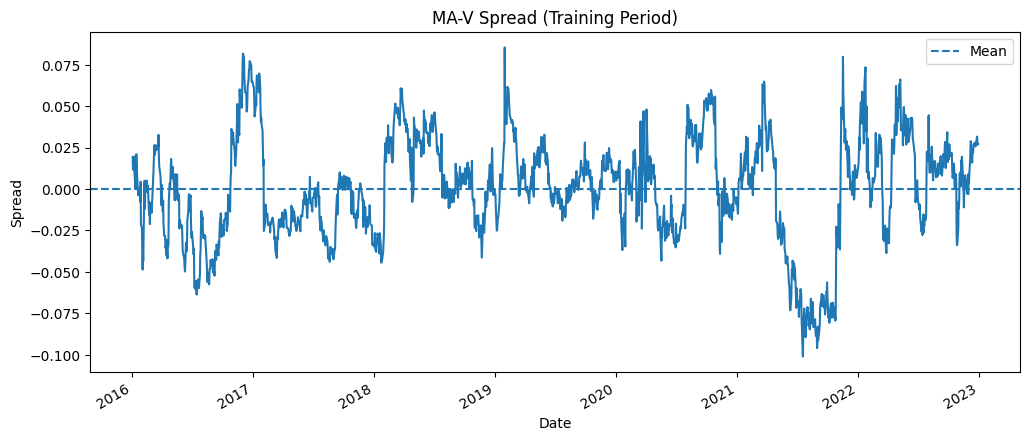

In [12]:
stock1 = "MA"
stock2 = "V"

# Log prices
y = np.log(train[stock1])
x = np.log(train[stock2])

# OLS regression
X = sm.add_constant(x)
model = sm.OLS(y, X).fit()

alpha = model.params.iloc[0]
beta = model.params.iloc[1]

print("Selected Pair:", stock1, "-", stock2)
print("Alpha:", round(alpha, 4))
print("Hedge Ratio (Beta):", round(beta, 4))

# Construct spread
spread_train = y - alpha - beta * x

# Plot spread
spread_train.plot(figsize=(12, 5))
plt.axhline(
    spread_train.mean(),
    linestyle="--",
    label="Mean"
)

plt.title("MA-V Spread (Training Period)")
plt.ylabel("Spread")
plt.legend()
plt.show()

In [13]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(spread_train)

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))

if adf_result[1] < 0.05:
    print("Result: Spread is stationary.")
else:
    print("Result: Spread is NOT stationary.")

ADF Statistic: -4.899
p-value: 3.5e-05
Result: Spread is stationary.


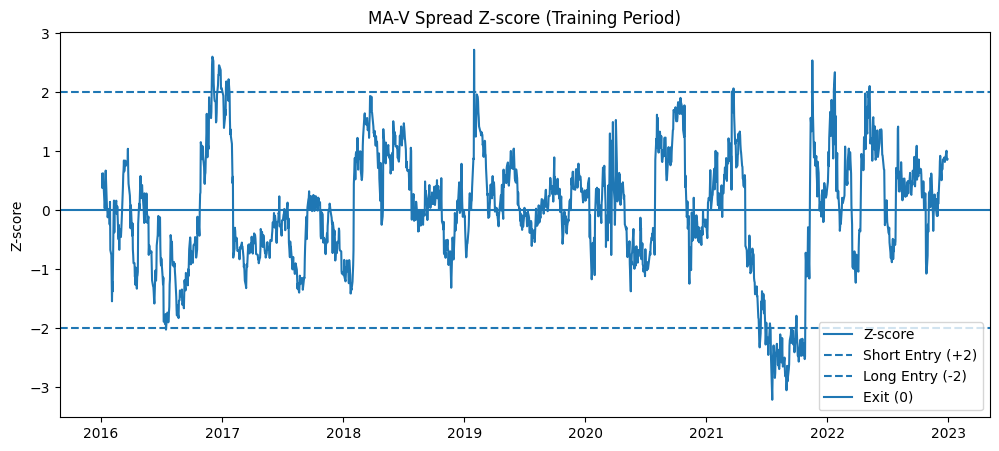

In [14]:
# Calculate Z-score of the spread

spread_mean = spread_train.mean()
spread_std = spread_train.std()

zscore_train = (spread_train - spread_mean) / spread_std

# Plot Z-score
plt.figure(figsize=(12, 5))

plt.plot(zscore_train, label="Z-score")

plt.axhline(2, linestyle="--", label="Short Entry (+2)")
plt.axhline(-2, linestyle="--", label="Long Entry (-2)")
plt.axhline(0, linestyle="-", label="Exit (0)")

plt.title("MA-V Spread Z-score (Training Period)")
plt.ylabel("Z-score")
plt.legend()

plt.show()

In [15]:
# Generate trading positions

position = pd.Series(0.0, index=zscore_train.index)

current_position = 0

for i in range(1, len(zscore_train)):
    
    z = zscore_train.iloc[i]
    previous_z = zscore_train.iloc[i - 1]

    # No position: look for entry
    if current_position == 0:
        
        if z < -2:
            current_position = 1       # Long spread
            
        elif z > 2:
            current_position = -1      # Short spread

    # Long spread: exit when Z-score returns to 0
    elif current_position == 1:
        
        if z >= 0:
            current_position = 0

    # Short spread: exit when Z-score returns to 0
    elif current_position == -1:
        
        if z <= 0:
            current_position = 0

    position.iloc[i] = current_position

print("Long days:", (position == 1).sum())
print("Short days:", (position == -1).sum())
print("Flat days:", (position == 0).sum())

Long days: 179
Short days: 161
Flat days: 1422


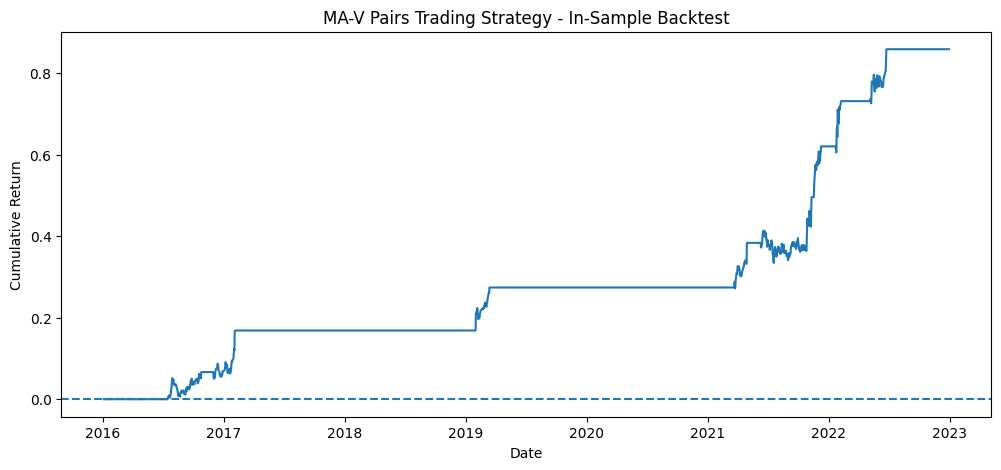

Total Return: 85.89%


In [16]:
# Daily log returns
ma_return = np.log(train["MA"]).diff()
v_return = np.log(train["V"]).diff()

# Return of the hedged spread
spread_return = ma_return - beta * v_return

# Use yesterday's position to avoid look-ahead bias
strategy_return = position.shift(1) * spread_return

strategy_return = strategy_return.fillna(0)

# Cumulative return
cumulative_return = np.exp(strategy_return.cumsum()) - 1

# Plot equity curve
plt.figure(figsize=(12, 5))

plt.plot(cumulative_return)

plt.title("MA-V Pairs Trading Strategy - In-Sample Backtest")
plt.ylabel("Cumulative Return")
plt.xlabel("Date")

plt.axhline(0, linestyle="--")

plt.show()

print(
    "Total Return:",
    f"{cumulative_return.iloc[-1]:.2%}"
)

In [17]:
# Performance metrics

trading_days = 252

# Annualized return
annualized_return = np.exp(
    strategy_return.mean() * trading_days
) - 1

# Annualized volatility
annualized_volatility = (
    strategy_return.std() * np.sqrt(trading_days)
)

# Sharpe ratio
sharpe_ratio = (
    strategy_return.mean()
    / strategy_return.std()
    * np.sqrt(trading_days)
)

# Equity curve
equity = np.exp(strategy_return.cumsum())

# Drawdown
running_max = equity.cummax()
drawdown = equity / running_max - 1

max_drawdown = drawdown.min()

# Total return
total_return = equity.iloc[-1] - 1

print(f"Total Return: {total_return:.2%}")
print(f"Annualized Return: {annualized_return:.2%}")
print(f"Annualized Volatility: {annualized_volatility:.2%}")
print(f"Sharpe Ratio: {sharpe_ratio:.2f}")
print(f"Max Drawdown: {max_drawdown:.2%}")

Total Return: 85.89%
Annualized Return: 9.27%
Annualized Volatility: 6.23%
Sharpe Ratio: 1.42
Max Drawdown: -5.62%


In [18]:
transaction_cost = 0.001  # 10 bps

trades = position.diff().abs().fillna(0)

costs = trades * transaction_cost

net_strategy_return = strategy_return - costs

net_equity = np.exp(net_strategy_return.cumsum())

net_total_return = net_equity.iloc[-1] - 1

print(f"Gross Total Return: {total_return:.2%}")
print(f"Net Total Return: {net_total_return:.2%}")
print(f"Total Transaction Cost: {costs.sum():.2%}")
print(f"Number of Position Changes: {(trades > 0).sum()}")

Gross Total Return: 85.89%
Net Total Return: 82.94%
Total Transaction Cost: 1.60%
Number of Position Changes: 16


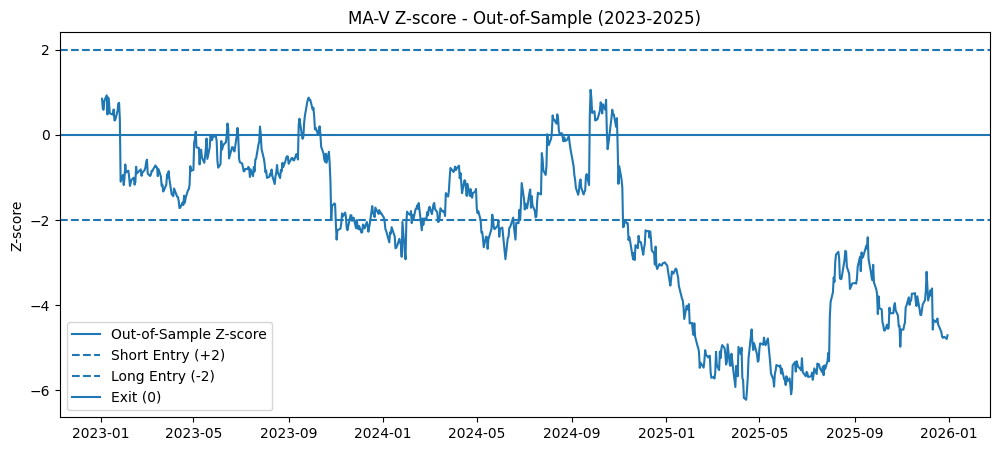

In [19]:
# Construct out-of-sample spread
# IMPORTANT: use alpha and beta estimated from training data

spread_test = (
    np.log(test["MA"])
    - alpha
    - beta * np.log(test["V"])
)

# Use training-period mean and std
zscore_test = (
    spread_test - spread_mean
) / spread_std

# Plot out-of-sample Z-score
plt.figure(figsize=(12, 5))

plt.plot(zscore_test, label="Out-of-Sample Z-score")

plt.axhline(2, linestyle="--", label="Short Entry (+2)")
plt.axhline(-2, linestyle="--", label="Long Entry (-2)")
plt.axhline(0, linestyle="-", label="Exit (0)")

plt.title("MA-V Z-score - Out-of-Sample (2023-2025)")
plt.ylabel("Z-score")
plt.legend()

plt.show()

In [20]:
# Generate out-of-sample trading positions

position_test = pd.Series(0.0, index=zscore_test.index)

current_position = 0

for i in range(1, len(zscore_test)):
    
    z = zscore_test.iloc[i]

    if current_position == 0:
        
        if z < -2:
            current_position = 1      # Long spread
            
        elif z > 2:
            current_position = -1     # Short spread

    elif current_position == 1:
        
        if z >= 0:
            current_position = 0

    elif current_position == -1:
        
        if z <= 0:
            current_position = 0

    position_test.iloc[i] = current_position


# Daily returns
ma_return_test = np.log(test["MA"]).diff()
v_return_test = np.log(test["V"]).diff()

spread_return_test = (
    ma_return_test - beta * v_return_test
)

# Avoid look-ahead bias
strategy_return_test = (
    position_test.shift(1) * spread_return_test
).fillna(0)


# Transaction costs
trades_test = position_test.diff().abs().fillna(0)

costs_test = trades_test * 0.001

net_return_test = strategy_return_test - costs_test


# Equity curve
equity_test = np.exp(net_return_test.cumsum())

total_return_test = equity_test.iloc[-1] - 1


# Sharpe ratio
sharpe_test = (
    net_return_test.mean()
    / net_return_test.std()
    * np.sqrt(252)
)


print(f"Out-of-Sample Total Return: {total_return_test:.2%}")
print(f"Out-of-Sample Sharpe Ratio: {sharpe_test:.2f}")
print(f"Position Changes: {(trades_test > 0).sum()}")

Out-of-Sample Total Return: -1.65%
Out-of-Sample Sharpe Ratio: -0.06
Position Changes: 3


In [21]:
# Test whether MA and V remain cointegrated out-of-sample

score_test, pvalue_test, _ = coint(
    np.log(test["MA"]),
    np.log(test["V"])
)

print(f"In-Sample Cointegration p-value: 0.000250")
print(f"Out-of-Sample Cointegration p-value: {pvalue_test:.6f}")

if pvalue_test < 0.05:
    print("Result: Pair remains cointegrated out-of-sample.")
else:
    print("Result: Cointegration relationship breaks down out-of-sample.")

In-Sample Cointegration p-value: 0.000250
Out-of-Sample Cointegration p-value: 0.142443
Result: Cointegration relationship breaks down out-of-sample.


In [22]:
def backtest_threshold(zscore, spread_return, entry):
    
    pos = pd.Series(0.0, index=zscore.index)
    current = 0
    
    for i in range(1, len(zscore)):
        z = zscore.iloc[i]
        
        if current == 0:
            if z < -entry:
                current = 1
            elif z > entry:
                current = -1
                
        elif current == 1:
            if z >= 0:
                current = 0
                
        elif current == -1:
            if z <= 0:
                current = 0
        
        pos.iloc[i] = current

    # Avoid look-ahead bias
    returns = pos.shift(1) * spread_return
    returns = returns.fillna(0)

    # Transaction costs
    trades = pos.diff().abs().fillna(0)
    net_returns = returns - trades * 0.001

    total_return = np.exp(net_returns.sum()) - 1

    if net_returns.std() > 0:
        sharpe = (
            net_returns.mean()
            / net_returns.std()
            * np.sqrt(252)
        )
    else:
        sharpe = np.nan

    return total_return, sharpe


threshold_results = []

for entry in [1.5, 2.0, 2.5]:
    
    total_ret, sharpe = backtest_threshold(
        zscore_train,
        spread_return,
        entry
    )
    
    threshold_results.append({
        "Entry Threshold": entry,
        "Total Return": total_ret,
        "Sharpe Ratio": sharpe
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,Entry Threshold,Total Return,Sharpe Ratio
0,1.5,1.186082,1.375775
1,2.0,0.829423,1.394180
2,2.5,0.436206,1.160124


In [23]:
summary = pd.DataFrame({
    "Metric": [
        "Cointegration p-value",
        "Total Return",
        "Sharpe Ratio"
    ],
    "In-Sample": [
        0.000250,
        0.8294,
        1.42
    ],
    "Out-of-Sample": [
        0.142443,
        -0.0165,
        -0.06
    ]
})

summary

,Metric,In-Sample,Out-of-Sample
0,Cointegration p-value,0.00025,0.142443
1,Total Return,0.82940,-0.016500
2,Sharpe Ratio,1.42000,-0.060000


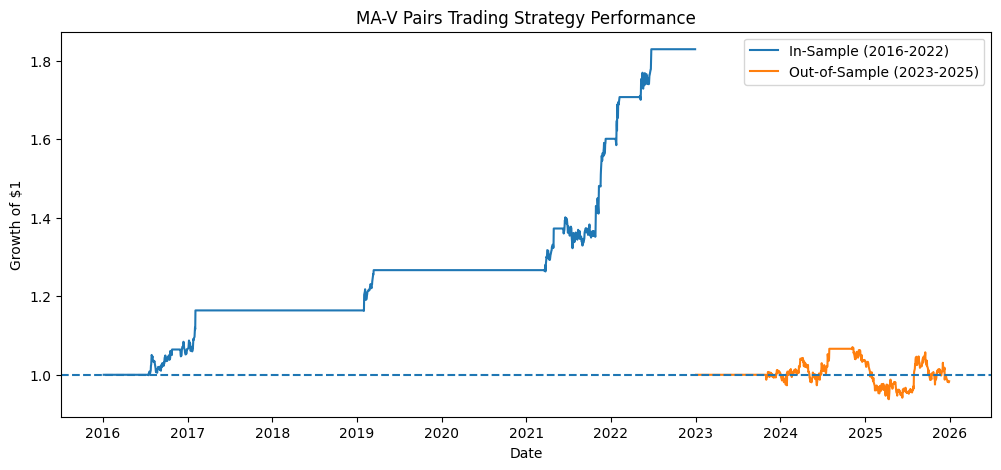

In [24]:
# Compare In-Sample and Out-of-Sample equity curves

in_sample_equity = np.exp(net_strategy_return.cumsum())
out_sample_equity = np.exp(net_return_test.cumsum())

# Normalize both to start at 1
in_sample_equity = in_sample_equity / in_sample_equity.iloc[0]
out_sample_equity = out_sample_equity / out_sample_equity.iloc[0]

plt.figure(figsize=(12, 5))

plt.plot(
    in_sample_equity,
    label="In-Sample (2016-2022)"
)

plt.plot(
    out_sample_equity,
    label="Out-of-Sample (2023-2025)"
)

plt.axhline(1, linestyle="--")

plt.title("MA-V Pairs Trading Strategy Performance")
plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.legend()

plt.show()

## Conclusion

This project developed a cointegration-based pairs trading strategy using a universe of 25 liquid S&P 500 equities.

The Engle-Granger cointegration test identified Mastercard (MA) and Visa (V) as the strongest candidate pair during the 2016–2022 in-sample period, with a cointegration p-value of 0.00025. An OLS regression was used to estimate the hedge ratio, and an ADF test confirmed that the resulting spread was stationary (p-value = 0.000035).

Using a Z-score mean-reversion strategy with ±2 entry thresholds and a zero exit threshold, the strategy generated an in-sample total return of 85.89%, with a Sharpe ratio of 1.42 and a maximum drawdown of -5.62%. After incorporating a 10 bps transaction cost assumption, the total return remained 82.94%.

However, out-of-sample performance deteriorated substantially. From 2023–2025, the strategy generated a total return of -1.65% and a Sharpe ratio of -0.06. The out-of-sample cointegration p-value increased to 0.1424, indicating that the historical cointegration relationship between MA and V was no longer statistically significant at the 5% level.

Parameter sensitivity analysis also showed that strategy performance varied across entry thresholds, highlighting the risk of parameter selection and overfitting.

Overall, the results demonstrate that strong in-sample statistical relationships do not necessarily persist out of sample. This highlights the importance of out-of-sample validation, transaction costs, parameter sensitivity analysis, and monitoring the stability of cointegration relationships when designing statistical arbitrage strategies.